# DEEP Practical Week 6 with solutions: Deep generative models

There's a lot in this week's practical. You don't necessarily need to do it all. Everyone should try exercises 2 and 3. Masters students should also try exercise 4. Exercise 1 is useful for helping your understanding and the result is somewhat intriguing.

1. Adversarial perturbations: break a digit classifier with an invisible change.
2. A simple GAN in 2D: learn to turn Gaussian noise into a spiral, and watch the generator and discriminator compete.
3. A GAN for images (DCGAN) on Fashion MNIST, including latent space interpolation.
4. A conditional GAN that generates the clothing class you ask for.

##1. Adversarial perturbations

You will start by creating an "adversarial perturbation" of an image in order to break a classifier. This means you will find a small offset that can be added to an image to change the class assigned to it by a classifier. We will do this using a pretrained LeNet for MNIST digit classification. The adversarial examples part of this week's lecture explains the idea. First, let's set up the network and load the pretrained weights. The code below will download the `LeNet_weights.pkl` file and then load it into the model.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [ ]:
!wget https://www-users.york.ac.uk/~waps101/PADL/LeNet_weights.pkl

--2026-11-06 18:31:32--  https://www-users.york.ac.uk/~waps101/PADL/LeNet_weights.pkl
Resolving www-users.york.ac.uk (www-users.york.ac.uk)... 144.32.129.58, 2001:630:61:180::1:13a
Connecting to www-users.york.ac.uk (www-users.york.ac.uk)|144.32.129.58|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 250572 (245K)
Saving to: ‘LeNet_weights.pkl’

LeNet_weights.pkl   100%[===================>] 244.70K   226KB/s    in 1.1s    

2026-11-06 18:31:34 (226 KB/s) - ‘LeNet_weights.pkl’ saved [250572/250572]



In [ ]:
class LeNet(nn.Module):
    def __init__(self):
        super(LeNet, self).__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_channels=1, out_channels=6, kernel_size=5, stride=1, padding=2),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(in_channels=6, out_channels=16, kernel_size=5, stride=1, padding=0),
            nn.Tanh(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Flatten(),
            nn.Linear(in_features=5*5*16,out_features=120),
            nn.Tanh(),
            nn.Linear(in_features=120,out_features=84),
            nn.Tanh(),
            nn.Linear(in_features=84,out_features=10)
        )

    def forward(self, x):
        x = self.net(x)
        return x

model = LeNet()
model.load_state_dict(torch.load('LeNet_weights.pkl', map_location='cpu'))
model.eval()  # this small exercise runs on the CPU

LeNet(
  (net): Sequential(
    (0): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): Tanh()
    (2): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
    (4): Tanh()
    (5): AvgPool2d(kernel_size=2, stride=2, padding=0)
    (6): Flatten(start_dim=1, end_dim=-1)
    (7): Linear(in_features=400, out_features=120, bias=True)
    (8): Tanh()
    (9): Linear(in_features=120, out_features=84, bias=True)
    (10): Tanh()
    (11): Linear(in_features=84, out_features=10, bias=True)
  )
)

You now have a network that is good at classifying the MNIST digit dataset. Let's take the first test image, run it through the network and check its classification and how confident it is.

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.79MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 135kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.28MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.7MB/s]


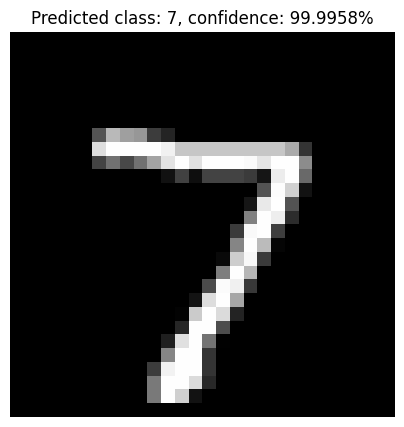

In [ ]:
test_data = datasets.MNIST(root = 'data', train = False, transform = transforms.ToTensor(), download=True)
# Extract the first test image (correct class=7)
image,label = test_data[0]
# Make a batch of just this image
images = image.unsqueeze(0)
# Run image through pretrained network
output = model(images)
# Find highest probability class
pred_y = torch.argmax(output, 1)
# Convert logits to probabilities
probs = nn.functional.softmax(output,dim=1)

figure = plt.figure(figsize=(5,5))
plt.title("Predicted class: {}, confidence: {:.4f}%".format(pred_y[0],probs[0,pred_y[0]]*100))
plt.axis("off")
plt.imshow(image[0,:], cmap="gray")
plt.show()

It's very confident that this is a seven!

**To do**: You now need to solve an optimisation problem to find the perturbation $\mathbf{r}$ to the input image $\mathbf{x}$ such that $\mathbf{x}+\mathbf{r}$ is classified as a zero instead of a seven. The loss that your optimisation will seek to minimise is a sum of two losses:

1. Cross entropy loss with the incorrect label of `[0]`.
2. A loss to keep the magnitude of the perturbation small (i.e. to change the image as little as possible). Using the sum of the squared value of all elements of $\mathbf{r}$ works ok for this.

The loss you will optimise should be the sum of these two losses with the second weighted by a parameter $c$. This parameter trades off how much it modifies the image against how much it can change the classification result. Start off with $c=1.0$.

The only thing you are optimising is $\mathbf{r}$. Look back at the week 1 practical if you can't remember how to use PyTorch to directly optimise a variable. Initialise $\mathbf{r}$ as all zeros.

During the optimisation, print out the value of the two losses. The magnitude of the perturbation will start off as zero so must increase in order to decrease the classification loss. You might need to play with the value of $c$ to get a desirable result. Also print out the current classification result so you can see when it switches its mind to class zero.

Once you think you have a good result, visualise the perturbed image and also the perturbation on its own. You can also try different incorrect classes. Can you get it to change its mind with a less obvious perturbation for other classes?

**Link to the lecture**: once you have a perturbation that works, try adding *random* noise of the same size instead (i.e. with the same sum of squares as your $\mathbf{r}$). Does the classifier change its mind? What does this tell you about the direction of the perturbation?

###Solution

In [ ]:
num_iterations = 200

# Initialise perturbation to zeros.
# Since we will optimise this variable, we need to set requires_grad to True.
r = torch.zeros_like(images, requires_grad=True)
# Create the incorrect label
y_incorrect = torch.tensor([0])
# Set the weight parameter. Because the perturbed image is kept in [0, 1], c = 1.0 is borderline here;
# c = 0.5 flips the prediction to 0 reliably while the change stays hard to see.
c = 0.5
# Initialise the optimiser to optimise only r
# (called 'optimiser' so that it does not hide the torch.optim module imported as 'optim')
optimiser = torch.optim.SGD([r], lr=0.01)

# Set up the loss function for multiclass classification
loss_func = nn.CrossEntropyLoss()

for i in range(num_iterations):
  # Keep the perturbed image a valid image (pixel values in [0, 1])
  output = model((images + r).clamp(0, 1))
  # Minimising this loss will push the image towards being classified wrongly
  class_loss = loss_func(output, y_incorrect)
  # This loss will try to keep the perturbation as small as possible
  mag_loss = torch.sum(r**2)
  loss = class_loss + c*mag_loss
  optimiser.zero_grad()
  loss.backward()
  optimiser.step()
  if (i+1) % 10 == 0:
    pred_y = torch.argmax(output, 1)
    print('Class loss: {:.4f}, Mag loss: {:.4f}, Pred: {}'.format(class_loss.item(), mag_loss.item(), pred_y[0].item()))

Class loss: 13.0713, Mag loss: 0.0127, Pred: 7
Class loss: 12.9335, Mag loss: 0.0481, Pred: 7
Class loss: 12.8076, Mag loss: 0.1010, Pred: 7
Class loss: 12.6901, Mag loss: 0.1672, Pred: 7
Class loss: 12.5801, Mag loss: 0.2431, Pred: 7
Class loss: 12.4768, Mag loss: 0.3260, Pred: 7
Class loss: 12.3861, Mag loss: 0.4079, Pred: 7
Class loss: 12.3068, Mag loss: 0.4881, Pred: 7
Class loss: 12.2343, Mag loss: 0.5660, Pred: 7
Class loss: 12.1666, Mag loss: 0.6436, Pred: 7
Class loss: 12.1028, Mag loss: 0.7210, Pred: 7
Class loss: 12.0428, Mag loss: 0.7972, Pred: 7
Class loss: 11.9860, Mag loss: 0.8725, Pred: 7
Class loss: 11.9331, Mag loss: 0.9439, Pred: 7
Class loss: 11.8813, Mag loss: 1.0162, Pred: 7
Class loss: 11.8324, Mag loss: 1.0870, Pred: 7
Class loss: 11.7859, Mag loss: 1.1561, Pred: 7
Class loss: 11.7417, Mag loss: 1.2210, Pred: 7
Class loss: 11.6991, Mag loss: 1.2869, Pred: 7
Class loss: 11.6584, Mag loss: 1.3487, Pred: 7


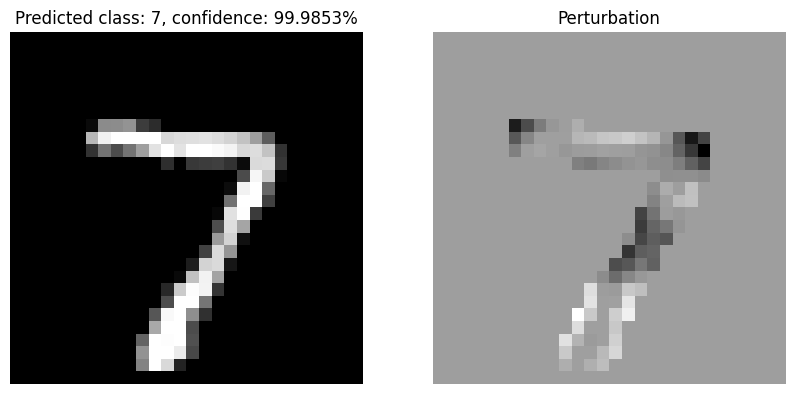

In [ ]:
perturbed = (images + r).clamp(0, 1).detach()
# Run image through pretrained network
output = model(perturbed)
# Find highest probability class
pred_y = torch.argmax(output, 1)
# Convert logits to probabilities
probs = nn.functional.softmax(output, dim=1)

figure = plt.figure(figsize=(10,5))
figure.add_subplot(1, 2, 1)
plt.title("Predicted class: {}, confidence: {:.4f}%".format(pred_y[0], probs[0,pred_y[0]]*100))
plt.axis("off")
plt.imshow(perturbed[0,0], cmap="gray")
figure.add_subplot(1, 2, 2)
plt.title("Perturbation")
plt.imshow(r[0,0].detach(), cmap="gray")
plt.axis("off")
plt.show()

###Solution: random noise of the same size

Random noise with the same sum of squares as $\mathbf{r}$ almost never changes the prediction. The adversarial perturbation works because it points in a very specific direction (the one that increases the loss fastest), not because it is large.

In [ ]:
noise = torch.randn_like(images)
noise = noise * r.detach().norm() / noise.norm()    # same size (L2 norm) as r
with torch.no_grad():
    for name, x in [("original", images), ("adversarial", perturbed), ("random noise", (images + noise).clamp(0, 1))]:
        p = nn.functional.softmax(model(x), dim=1)
        print("{:>12}: predicted {}, P(7) = {:.3f}, P(0) = {:.3f}".format(name, p.argmax(1).item(), p[0, 7].item(), p[0, 0].item()))

    original: predicted 7, P(7) = 1.000, P(0) = 0.000
 adversarial: predicted 7, P(7) = 1.000, P(0) = 0.000
random noise: predicted 7, P(7) = 1.000, P(0) = 0.000


## 2. A simple GAN in 2D

Before training a GAN on images, let's train one on data we can actually see. Our "dataset" is a set of 2D points lying on a noisy spiral. The generator takes 2D Gaussian noise $\mathbf{z}$ and maps it to a 2D point. The discriminator takes a 2D point and outputs the probability that it came from the real data.

Both networks are small fully connected networks, so this trains on the CPU in under a minute. You don't need a GPU for this exercise.

First, let's create the data and look at it.

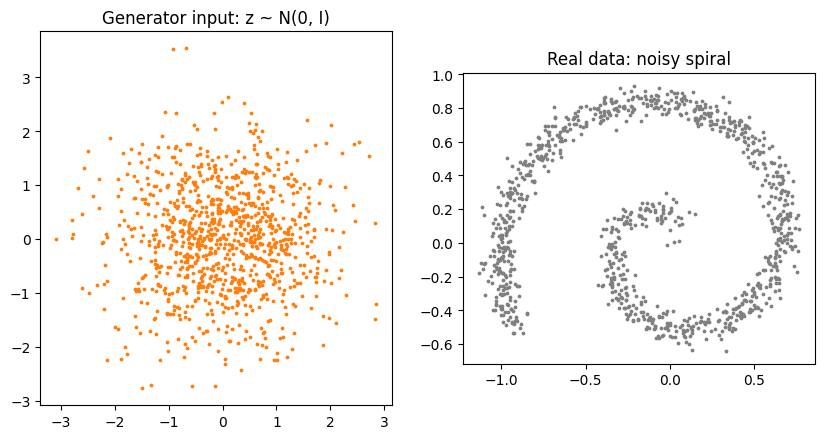

In [ ]:
import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

torch.manual_seed(0)

def sample_spiral(n, noise=0.05):
    # Points along a spiral (more points further out, so the density is roughly even), plus Gaussian noise
    t = torch.sqrt(torch.rand(n)) * 3 * np.pi + 0.5
    x = torch.stack([t * torch.cos(t), t * torch.sin(t)], 1) / (3 * np.pi)
    return x + noise * torch.randn(n, 2)

real = sample_spiral(1000)
z = torch.randn(1000, 2)

figure = plt.figure(figsize=(10, 5))
figure.add_subplot(1, 2, 1)
plt.scatter(z[:, 0], z[:, 1], s=3, c="tab:orange")
plt.title("Generator input: z ~ N(0, I)")
plt.gca().set_aspect("equal")
figure.add_subplot(1, 2, 2)
plt.scatter(real[:, 0], real[:, 1], s=3, c="gray")
plt.title("Real data: noisy spiral")
plt.gca().set_aspect("equal")
plt.show()

The generator has to learn a function that *bends* the Gaussian blob on the left into the spiral on the right. Note that nothing tells it which noise point should go to which spiral point. It only gets feedback from the discriminator.

Here are the two networks, and a helper function that draws the real points (grey), the generated points (orange) and the discriminator's output as a background colour (red = "real", blue = "fake").

In [ ]:
hidden = 64

G = nn.Sequential(                      # generator: 2D noise -> 2D point
    nn.Linear(2, hidden), nn.LeakyReLU(0.2),
    nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
    nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
    nn.Linear(hidden, 2)
)

D = nn.Sequential(                      # discriminator: 2D point -> probability of being real
    nn.Linear(2, hidden), nn.LeakyReLU(0.2),
    nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
    nn.Linear(hidden, hidden), nn.LeakyReLU(0.2),
    nn.Linear(hidden, 1), nn.Sigmoid()
)

grid = torch.stack(torch.meshgrid(torch.linspace(-1.3, 1.3, 150), torch.linspace(-1.3, 1.3, 150), indexing="xy"), -1)

def show(ax, step):
    with torch.no_grad():
        d_map = D(grid.view(-1, 2)).view(150, 150)
        fake = G(torch.randn(1000, 2))
    ax.contourf(grid[..., 0], grid[..., 1], d_map, levels=20, cmap="coolwarm", vmin=0, vmax=1, alpha=0.6)
    real = sample_spiral(1000)
    ax.scatter(real[:, 0], real[:, 1], s=2, c="gray")
    ax.scatter(fake[:, 0], fake[:, 1], s=2, c="tab:orange")
    ax.set_title("step {}".format(step))
    ax.set_xlim(-1.3, 1.3); ax.set_ylim(-1.3, 1.3); ax.set_aspect("equal"); ax.axis("off")

**To do**: complete the training loop below. Each step has the two parts from the lecture:

1. **Update the discriminator.** Real points should get the label 1 and generated points the label 0. Use `fake.detach()` here, so that this step does not change the generator.
2. **Update the generator.** Pass the generated points through the discriminator again and use the label 1 (i.e. the generator wants the discriminator to say "real"). This is the non-saturating generator loss.

Use `nn.BCELoss()` for both. If you get stuck, the image GAN in exercise 3 has a complete training loop that follows the same pattern.

The loop draws the state every 500 steps, so you can watch the orange points move onto the spiral.

step 500: loss_D 1.386, loss_G 0.697
step 1000: loss_D 1.332, loss_G 0.705
step 1500: loss_D 1.388, loss_G 0.691
step 2000: loss_D 1.388, loss_G 0.707
step 2500: loss_D 1.389, loss_G 0.717
step 3000: loss_D 1.386, loss_G 0.693


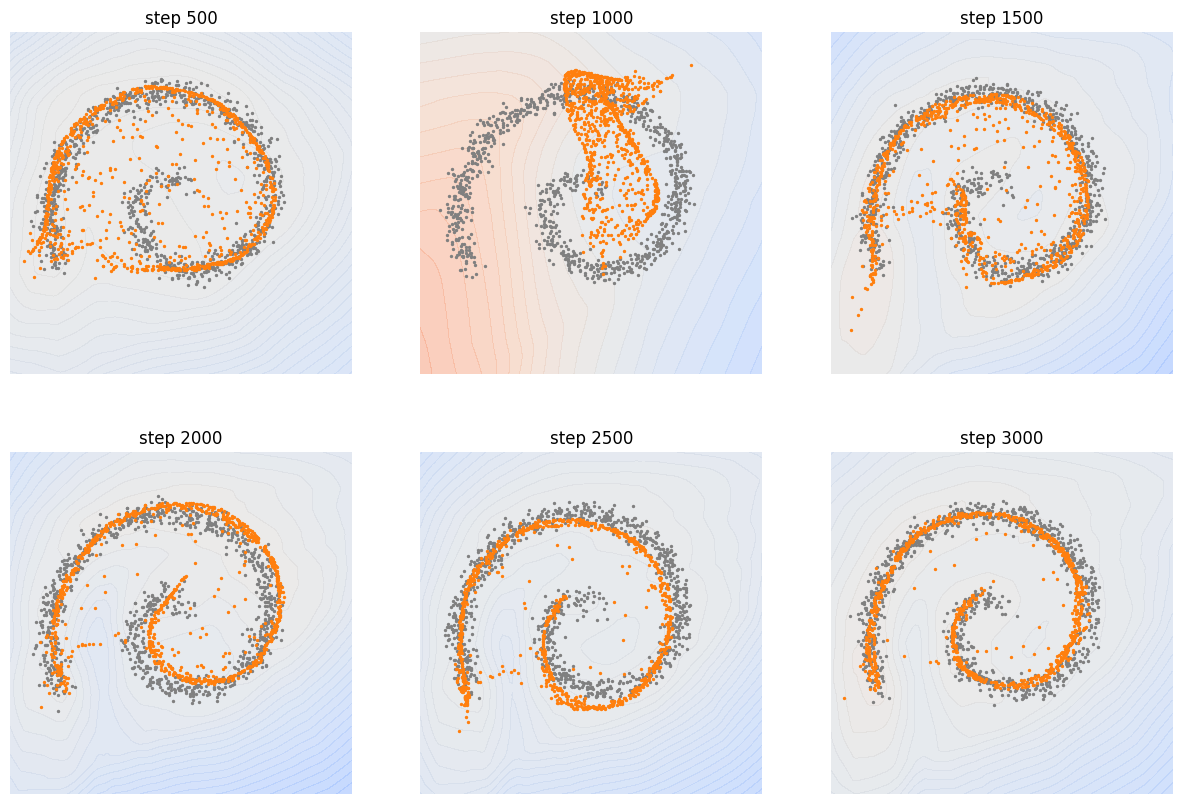

In [ ]:
criterion = nn.BCELoss()
optimizerG = torch.optim.Adam(G.parameters(), lr=1e-3, betas=(0.5, 0.999))
optimizerD = torch.optim.Adam(D.parameters(), lr=1e-3, betas=(0.5, 0.999))
batch_size2d = 256
num_steps = 3000
ones = torch.ones(batch_size2d, 1)
zeros = torch.zeros(batch_size2d, 1)

figure, axes = plt.subplots(2, 3, figsize=(15, 10))
for step in range(1, num_steps + 1):
    real = sample_spiral(batch_size2d)
    z = torch.randn(batch_size2d, 2)
    fake = G(z)

    # (1) Update the discriminator
    lossD = criterion(D(real), ones) + criterion(D(fake.detach()), zeros)
    optimizerD.zero_grad()
    lossD.backward()
    optimizerD.step()

    # (2) Update the generator
    lossG = criterion(D(fake), ones)
    optimizerG.zero_grad()
    lossG.backward()
    optimizerG.step()

    if step % 500 == 0:
        print("step {}: loss_D {:.3f}, loss_G {:.3f}".format(step, lossD.item(), lossG.item()))
        show(axes.flat[step // 500 - 1], step)
plt.show()

**Things to look at and try**:

1. Watch the background colour. Early on, the discriminator separates the orange blob from the grey spiral easily. What happens to its output near the spiral as training goes on? What would a perfect generator do to the discriminator's output?
2. Look at the end of training. Does the generator cover the whole spiral, including the inner end? Are there orange points *between* the arms of the spiral?
3. Unlike most networks you have trained, the losses do not steadily go down. Why not?
4. Re-run with a learning rate of `1e-2`, or with `hidden = 8`. What changes? Do you see any signs of the training problems from the lecture (oscillation, or the generator only covering part of the data)?

###Solution: discussion

1. As the generator improves, the orange points move onto the spiral and the discriminator becomes less sure: the background near the spiral moves towards 0.5 (white). For a perfect generator the real and generated distributions are the same, so the best the discriminator can do is output 0.5 everywhere.
2. Usually the generator covers most of the spiral, but the inner end is often thin or missing, and you will often see a few points between the arms. The generator is a continuous function of a connected Gaussian blob, so its output is also "connected": to put points on two arms it has to pass through the gap between them. A good generator makes the bridge very thin (it sends very little probability mass there), but it cannot remove it completely.
3. The two networks are playing a game. When one improves, the other's loss goes up. There is no single loss being minimised, so the losses oscillate rather than decrease. This is why GAN losses are a poor guide to sample quality.
4. With a large learning rate training is much less stable: the orange points jump around and may collapse onto part of the spiral (partial mode collapse). With `hidden = 8` the generator is too simple to bend the blob into a spiral, so it only fits a rough curve.

##3. A GAN for images (DCGAN)

Now let's scale the same idea up to images. We're going to train a GAN using the same Fashion MNIST dataset as last week. The training loop has exactly the same two steps as in exercise 2; only the networks change (convolutional instead of fully connected). We'll use the built-in dataloader this time. A few things to note:
1. for a GAN, we only need a training set (a validation set doesn't really make any sense in the context of a GAN)
2. the dataset is originally 28 x 28 images, I've padded this to 32 x 32 using the `transforms.CenterCrop` transform (it made it easier to reuse the DCGAN architecture later).
3. the GAN trains better if you normalise your image data to be scaled between -1 and 1 (rather than 0 and 1). This is done with `transforms.Normalize`.

Let's start by importing everything we need, setting up some parameters and setting up the data loader.

Note: training the GAN is slow. You might want to choose Edit -> Notebook settings -> Hardware accelerator -> GPU now.

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import datasets
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

# Define some parameters
batch_size = 100
nz = 100 # Size of z latent vector (i.e. size of generator input)
ngf = 64 # Size of feature maps in generator
ndf = 64 # Size of feature maps in discriminator
num_epochs = 5 # Number of training epochs
lr = 0.0002 # Learning rate for optimizers
beta1 = 0.5 # Beta1 hyperparam for Adam optimizers

# Set up the dataset and dataloader
transform = transforms.Compose([transforms.ToTensor(),transforms.CenterCrop(32),transforms.Normalize(0.5,0.5)])
train_data = datasets.FashionMNIST(root = 'data', train = True, transform = transform, download = True)
dataloader = torch.utils.data.DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=1)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

100%|██████████| 26.4M/26.4M [00:02<00:00, 11.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 170kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.30MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.22MB/s]


As last week, let's grab a batch of images and visualise the first 25 images. I've negated the image brightness to put the images back to how they originally looked - this is a nicer way to visualise them. You can use this code as a starting point for the visualisation tasks below.

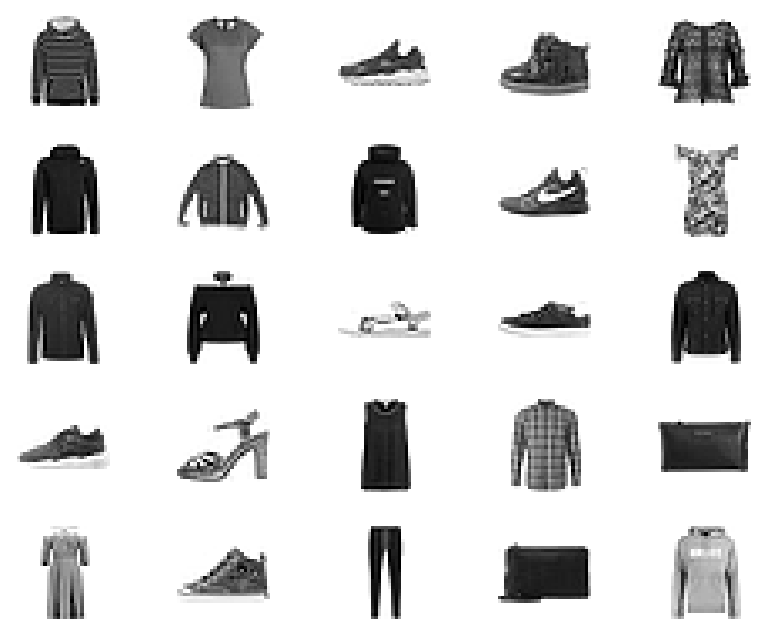

In [ ]:
images, labels = next(iter(dataloader))

figure = plt.figure(figsize=(10, 8))
cols, rows = 5, 5
for i in range(cols * rows):
    figure.add_subplot(rows, cols, i+1)
    plt.axis("off")
    plt.imshow(0.5-0.5*images[i,:].squeeze(), cmap="gray")
plt.show()

###Generator architecture

I have roughly followed the DCGAN architecture. The Generator takes as input a latent (`z`) vector which has `nz` dimensions. Via an expansive network with transposed convolutions, it converts this into a 32 x 32 image. To map the final output to the range -1..1 we use the Tanh activation function.

In [ ]:
class Generator(nn.Module):
    def __init__(self):
        super(Generator, self).__init__()
        self.main = nn.Sequential(
            # input is Z of size B x nz x 1 x 1, we put this directly into a transposed convolution
            nn.ConvTranspose2d( nz, ngf * 4, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # Size: B x (ngf*4) x 4 x 4
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # Size: B x (ngf*2) x 8 x 8
            nn.ConvTranspose2d( ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # Size: B x (ngf) x 16 x 16
            nn.ConvTranspose2d( ngf, 1, 4, 2, 1, bias=False),
            # Size: B x 1 x 32 x 32
            nn.Tanh()
        )

    def forward(self, input):
        return self.main(input)

netG = Generator()
netG = netG.to(device)

###Discriminator architecture

The discriminator is a conventional binary classification CNN: it takes an image as input and outputs the probability that the image is real. I've again followed the DCGAN architecture which uses something you haven't seen before: LeakyReLU. This is a variant on ReLU where negative values are allowed to "leak" through, albeit scaled down. Everything else you should have seen before.

In [ ]:
class Discriminator(nn.Module):
    def __init__(self):
        super(Discriminator, self).__init__()
        self.main = nn.Sequential(
            # state size. 1 x 32 x 32
            nn.Conv2d(1, ndf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf) x 16 x 16
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*2) x 8 x 8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*4) x 4 x 4
            nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input):
        return self.main(input)

netD = Discriminator()
netD = netD.to(device)

###GAN training

We're now ready to train our GAN. The training loop for a GAN is pretty complicated so look through the following code carefully and read the comments. It follows exactly the same two steps as your 2D GAN in exercise 2, and the GAN training part of this week's lecture. You can try running it for a while to train your own GAN but it's slow and below I provide some pretrained weights. Note: even though the data loader is returning labels, we're not using them here. A GAN doesn't need labels.

In [ ]:
# Initialize BCELoss function
criterion = nn.BCELoss()

# Establish convention for real and fake labels during training
real_label = 1.
fake_label = 0.

# Setup Adam optimizers for both G and D
optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))

# Training Loop

print("Starting Training Loop...")
# For each epoch
for epoch in range(num_epochs):
    # For each batch in the dataloader
    for i, (images,labels) in enumerate(dataloader, 0):

        ############################
        # (1) Update D network: maximize log(D(x)) + log(1 - D(G(z)))
        ###########################
        ## Train with all-real batch
        netD.zero_grad()
        # Format batch
        real_images = images.to(device)
        label = torch.full((batch_size,), real_label, dtype=torch.float, device=device)
        # Forward pass real batch through D
        output = netD(real_images).view(-1)
        # Calculate loss on all-real batch
        errD_real = criterion(output, label)
        # Calculate gradients for D in backward pass
        errD_real.backward()
        D_x = output.mean().item()

        ## Train with all-fake batch
        # Generate batch of latent vectors
        z = torch.randn(batch_size, nz, 1, 1, device=device)
        # Generate fake image batch with G
        fake = netG(z)
        label.fill_(fake_label)
        # Classify all fake batch with D
        output = netD(fake.detach()).view(-1)
        # Calculate D's loss on the all-fake batch
        errD_fake = criterion(output, label)
        # Calculate the gradients for this batch, accumulated (summed) with previous gradients
        errD_fake.backward()
        D_G_z1 = output.mean().item()
        # Compute error of D as sum over the fake and the real batches
        errD = errD_real + errD_fake
        # Update D
        optimizerD.step()

        ############################
        # (2) Update G network: maximize log(D(G(z)))
        ###########################
        netG.zero_grad()
        label.fill_(real_label)  # fake labels are real for generator cost
        # Since we just updated D, perform another forward pass of all-fake batch through D
        output = netD(fake).view(-1)
        # Calculate G's loss based on this output
        errG = criterion(output, label)
        # Calculate gradients for G
        errG.backward()
        D_G_z2 = output.mean().item()
        # Update G
        optimizerG.step()

        # Output training stats
        if i % 50 == 0:
            print('[%d/%d][%d/%d]\tLoss_D: %.4f\tLoss_G: %.4f\tD(x): %.4f\tD(G(z)): %.4f / %.4f'
                  % (epoch+1, num_epochs, i, len(dataloader),
                     errD.item(), errG.item(), D_x, D_G_z1, D_G_z2))

Starting Training Loop...
[1/5][0/600]	Loss_D: 1.4125	Loss_G: 1.2075	D(x): 0.5261	D(G(z)): 0.5229 / 0.3081
[1/5][50/600]	Loss_D: 0.0242	Loss_G: 5.6011	D(x): 0.9872	D(G(z)): 0.0101 / 0.0039
[1/5][100/600]	Loss_D: 0.0036	Loss_G: 6.4897	D(x): 0.9987	D(G(z)): 0.0023 / 0.0016
[1/5][150/600]	Loss_D: 0.0031	Loss_G: 6.8069	D(x): 0.9989	D(G(z)): 0.0020 / 0.0011
[1/5][200/600]	Loss_D: 0.3248	Loss_G: 6.4056	D(x): 0.9130	D(G(z)): 0.1855 / 0.0034
[1/5][250/600]	Loss_D: 0.8474	Loss_G: 4.4608	D(x): 0.8584	D(G(z)): 0.4637 / 0.0205
[1/5][300/600]	Loss_D: 0.5443	Loss_G: 4.1150	D(x): 0.9245	D(G(z)): 0.3444 / 0.0246
[1/5][350/600]	Loss_D: 0.5811	Loss_G: 1.9233	D(x): 0.6598	D(G(z)): 0.0950 / 0.1773
[1/5][400/600]	Loss_D: 0.5545	Loss_G: 2.4426	D(x): 0.7757	D(G(z)): 0.2215 / 0.1090
[1/5][450/600]	Loss_D: 0.4885	Loss_G: 2.4162	D(x): 0.8039	D(G(z)): 0.2134 / 0.1087
[1/5][500/600]	Loss_D: 0.6063	Loss_G: 2.2820	D(x): 0.7032	D(G(z)): 0.1849 / 0.1307
[1/5][550/600]	Loss_D: 0.4761	Loss_G: 2.2567	D(x): 0.8540	D(G(z)

###Visualise GAN output

**To do**:

Generate some random latent codes, pass them through the generator to get images and then visualise them like we visualised the random training images above.

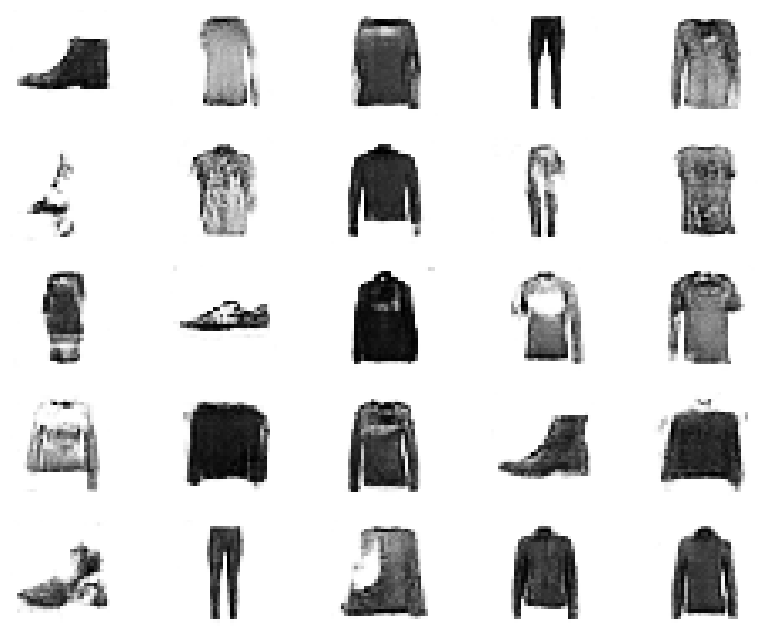

In [ ]:
# Solution
z = torch.randn(25,nz,1,1,device=device)
with torch.no_grad():
  images = netG(z)

figure = plt.figure(figsize=(10, 8))
cols, rows = 5, 5
for i in range(cols * rows):
    figure.add_subplot(rows, cols, i+1)
    plt.axis("off")
    plt.imshow(0.5-0.5*images[i,:].cpu().detach().squeeze(), cmap="gray")
plt.show()

###Loading pretrained weights

The above training loop is starting to take quite a lot of time, even using a GPU. 5 epochs is not enough for good results. So I've pretrained a network for you that I trained for 100 epochs. Download my pretrained weights and load them into your network, then try running your visualisation code again. Are the results noticeably better?

In [ ]:
!wget https://www-users.york.ac.uk/~waps101/PADL/netG.pkl
netG.load_state_dict(torch.load('netG.pkl',map_location=torch.device(device)))
netG.eval()

--2026-11-06 18:34:14--  https://www-users.york.ac.uk/~waps101/PADL/netG.pkl
Resolving www-users.york.ac.uk (www-users.york.ac.uk)... 144.32.129.58, 2001:630:61:180::1:13a
Connecting to www-users.york.ac.uk (www-users.york.ac.uk)|144.32.129.58|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4276652 (4.1M)
Saving to: ‘netG.pkl’

netG.pkl            100%[===================>]   4.08M   743KB/s    in 6.8s    

2026-11-06 18:34:22 (618 KB/s) - ‘netG.pkl’ saved [4276652/4276652]



Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 256, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): Tanh()
  )
)

###Latent space interpolation

One of the interesting things about GANs is that the latent space of the generator provides a set of parameters that can be manipulated to change the appearance of the image in a smooth way. Walking around in the latent space results in an image that gradually varies hopefully remaining plausible all the time. The easiest way to try this out is by linearly interpolating between two samples.

**To do**:

Write some code that starts by generating two random latent codes, `z1` and `z2`. Now create a batch of 9 latent codes that linearly interpolates between them so that the first element in the batch is equal to `z1`, the ninth is equal to `z2` and the fifth (i.e. the middle element) is equal to `0.5*z1 + 0.5*z2`. Pass the batch of latent codes through your generator (remember to put the generator in eval mode first with `netG.eval()` so that the batchnorm layers use the learnt means/stds). Now display the resulting images (adapt the code we've used previously for visualising images from a batch). You should see a gradual transition from one image to the other and the intermediates should look reasonable (although it's hard to interpolate from a handbag to a pair of trousers!)

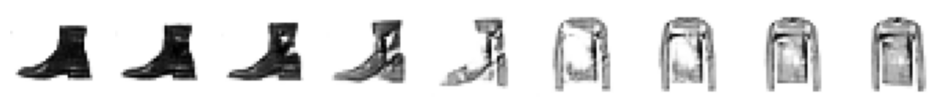

In [ ]:
# Solution

nsamples = 9
z1 = torch.randn(1, nz, 1, 1, device=device)
z2 = torch.randn(1, nz, 1, 1, device=device)
z = torch.zeros(nsamples,nz,1,1,device=device)
for i in range(nsamples):
  w2 = i/(nsamples-1)   # weight on z2 goes 0 -> 1
  w1 = 1-w2             # so the first code is z1 and the last is z2
  z[i,:,:,:] = w1*z1 + w2*z2
netG.eval()
with torch.no_grad():
  images = netG(z)

figure = plt.figure(figsize=(12, 4))
for i in range(nsamples):
    figure.add_subplot(1, nsamples, i+1)
    plt.axis("off")
    plt.imshow(0.5-0.5*images[i,:].squeeze().cpu().detach(), cmap="gray")
plt.show()

##4. Create a conditional GAN (highly recommended for Masters students)

I would now like you to extend the image GAN from exercise 3 to make it into a conditional GAN. This means that the generator takes both a z latent vector and also a class label and generates an image of the appropriate class. The discriminator takes an image plus the class label and returns the probability that this is a real image of that class. There are many ways you could engineer the generator and discriminator architectures to take labels as input but here is my suggestion:
- Use a `torch.nn.Embedding` layer to turn the class label into a feature vector. A dimensionality of 50 for this feature vector works well.
- In the generator you can then just concatenate this embedding with the `z` vector and feed it into the same generator architecture as above.
- In the discriminator, use another linear layer to transform the embedding up to size 32 x 32. You can then just concatenate this as an additional channel to the image that you pass into the same architecture as above (just with two input channels rather than 1).
- The training loop is very similar to above but now you pass the real labels along with the real images to the discriminator. When you create a random batch of fake images, you need to generate some random labels. These should also be passed to the discriminator.

Once you get it to train, try visualising random output for each class. For example, fix the label to zero then generate 8 images, then repeat for labels 1-9. You should see the right class but random variation within that class when you vary z.

###Solution: Conditional generator architecture

In [ ]:
class ConditionalGenerator(nn.Module):
    def __init__(self):
        super(ConditionalGenerator, self).__init__()
        self.embedding = nn.Embedding(10, 50)
        self.mixer = nn.Sequential(
            nn.Linear(50+nz,128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Linear(128,128),
            nn.BatchNorm1d(128),
            nn.ReLU()
        )
        self.main = nn.Sequential(
            # input is the mixed (z, label) vector of size B x 128 x 1 x 1
            nn.ConvTranspose2d( 128, ngf * 4, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # state size. (ngf*4) x 4 x 4
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # state size. (ngf*2) x 8 x 8
            nn.ConvTranspose2d( ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # state size. (ngf) x 16 x 16
            nn.ConvTranspose2d( ngf, 1, 4, 2, 1, bias=False),
            # state size. 1 x 32 x 32
            nn.Tanh()
        )

    def forward(self, z, label):
        classembedding = self.embedding(label) # Size B x 50
        mixedembedding = self.mixer(torch.cat((z.view(z.shape[0], -1),classembedding),1))  # view (not squeeze) also works for a batch of 1
        input = mixedembedding.unsqueeze(-1).unsqueeze(-1) # Size B x 128 x 1 x 1
        return self.main(input)

netCG = ConditionalGenerator()
netCG = netCG.to(device)

###Solution: conditional discriminator architecture

In [ ]:
class ConditionalDiscriminator(nn.Module):
    def __init__(self):
        super(ConditionalDiscriminator, self).__init__()
        self.embedding = nn.Sequential(
            nn.Embedding(10, 50),
            nn.Linear(50,32*32)
        )
        self.main = nn.Sequential(
            # state size. 2 x 32 x 32
            nn.Conv2d(2, ndf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf) x 16 x 16
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*2) x 8 x 8
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # state size. (ndf*4) x 4 x 4
            nn.Conv2d(ndf * 4, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, image, label):
        classembedding = self.embedding(label) # Size B x 32^2
        classembedding = classembedding.view(classembedding.shape[0],1,32,32)
        input = torch.cat((image,classembedding),1) # Size B x 2 x 32 x 32
        return self.main(input)

netCD = ConditionalDiscriminator()

netCD = netCD.to(device)

###Solution: training code

In [ ]:
# Initialize BCELoss function
criterion = nn.BCELoss()

# Setup Adam optimizers for both G and D
optimizerCD = optim.Adam(netCD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerCG = optim.Adam(netCG.parameters(), lr=lr, betas=(beta1, 0.999))

# Training Loop
print("Starting Training Loop...")
# For each epoch
for epoch in range(num_epochs):
    # For each batch in the dataloader
    for i, (images,labels) in enumerate(dataloader, 0):

        ############################
        # (1) Update D network: maximize log(D(x)) + log(1 - D(G(z)))
        ###########################
        ## Train with all-real batch
        netCD.zero_grad()
        # Format batch
        real_images, labels = images.to(device), labels.to(device)
        label = torch.full((batch_size,), real_label, dtype=torch.float, device=device)
        # Forward pass real batch through D
        output = netCD(real_images,labels).view(-1)
        # Calculate loss on all-real batch
        errD_real = criterion(output, label)
        # Calculate gradients for D in backward pass
        errD_real.backward()
        D_x = output.mean().item()

        ## Train with all-fake batch
        # Generate batch of latent vectors
        z = torch.randn(batch_size, nz, 1, 1, device=device)
        # Generate random labels
        random_labels = torch.randint(high=10,size=(batch_size,),device=device)
        # Generate fake image batch with G
        fake = netCG(z,random_labels)
        label.fill_(fake_label)
        # Classify all fake batch with D
        output = netCD(fake.detach(),random_labels).view(-1)
        # Calculate D's loss on the all-fake batch
        errD_fake = criterion(output, label)
        # Calculate the gradients for this batch, accumulated (summed) with previous gradients
        errD_fake.backward()
        D_G_z1 = output.mean().item()
        # Compute error of D as sum over the fake and the real batches
        errD = errD_real + errD_fake
        # Update D
        optimizerCD.step()

        ############################
        # (2) Update G network: maximize log(D(G(z)))
        ###########################
        netCG.zero_grad()
        label.fill_(real_label)  # fake labels are real for generator cost
        # Since we just updated D, perform another forward pass of all-fake batch through D
        # Use the SAME random labels that the fake images were generated with
        output = netCD(fake,random_labels).view(-1)
        # Calculate G's loss based on this output
        errG = criterion(output, label)
        # Calculate gradients for G
        errG.backward()
        D_G_z2 = output.mean().item()
        # Update G
        optimizerCG.step()

        # Output training stats
        if i % 50 == 0:
            print('[%d/%d][%d/%d]\tLoss_D: %.4f\tLoss_G: %.4f\tD(x): %.4f\tD(G(z)): %.4f / %.4f'
                  % (epoch+1, num_epochs, i, len(dataloader),
                     errD.item(), errG.item(), D_x, D_G_z1, D_G_z2))

Starting Training Loop...
[1/5][0/600]	Loss_D: 1.4169	Loss_G: 1.3868	D(x): 0.5336	D(G(z)): 0.5319 / 0.2620
[1/5][50/600]	Loss_D: 0.4822	Loss_G: 4.4397	D(x): 0.6892	D(G(z)): 0.0442 / 0.0492
[1/5][100/600]	Loss_D: 0.7603	Loss_G: 2.9468	D(x): 0.7688	D(G(z)): 0.3203 / 0.0583
[1/5][150/600]	Loss_D: 1.1038	Loss_G: 2.9795	D(x): 0.7899	D(G(z)): 0.5643 / 0.0590
[1/5][200/600]	Loss_D: 1.1149	Loss_G: 1.0172	D(x): 0.4570	D(G(z)): 0.2033 / 0.3794
[1/5][250/600]	Loss_D: 1.2259	Loss_G: 1.4649	D(x): 0.6895	D(G(z)): 0.5573 / 0.2453
[1/5][300/600]	Loss_D: 1.1298	Loss_G: 1.0080	D(x): 0.5928	D(G(z)): 0.4105 / 0.3721
[1/5][350/600]	Loss_D: 1.0416	Loss_G: 1.3959	D(x): 0.5948	D(G(z)): 0.3698 / 0.2636
[1/5][400/600]	Loss_D: 1.1086	Loss_G: 1.8629	D(x): 0.6850	D(G(z)): 0.4965 / 0.1756
[1/5][450/600]	Loss_D: 1.0273	Loss_G: 2.0559	D(x): 0.6846	D(G(z)): 0.4435 / 0.1414
[1/5][500/600]	Loss_D: 1.2251	Loss_G: 1.0128	D(x): 0.4694	D(G(z)): 0.2865 / 0.3860
[1/5][550/600]	Loss_D: 1.4459	Loss_G: 1.2352	D(x): 0.5192	D(G(z)

###Solution: visualisation

This code downloads my pretrained network then visualises 8 random images from each class. Note: my pretrained network shows little variety within each class (a form of mode collapse). If you train your own network with the training code above, compare how much variety you get within each class.

--2026-11-06 18:36:34--  https://www-users.york.ac.uk/~waps101/PADL/netCG.pkl
Resolving www-users.york.ac.uk (www-users.york.ac.uk)... 144.32.129.58, 2001:630:61:180::1:13a
Connecting to www-users.york.ac.uk (www-users.york.ac.uk)|144.32.129.58|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 4889535 (4.7M)
Saving to: ‘netCG.pkl’

netCG.pkl           100%[===================>]   4.66M   718KB/s    in 7.6s    

2026-11-06 18:36:43 (625 KB/s) - ‘netCG.pkl’ saved [4889535/4889535]



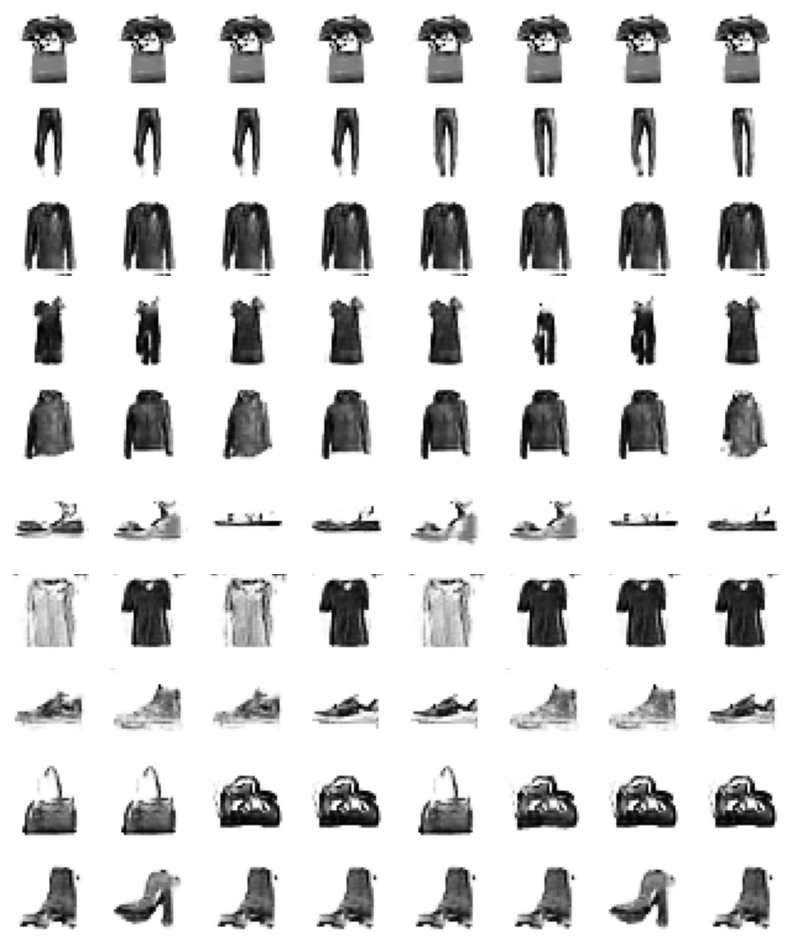

In [ ]:
!wget https://www-users.york.ac.uk/~waps101/PADL/netCG.pkl
netCG.load_state_dict(torch.load('netCG.pkl',map_location=torch.device(device)))
netCG.eval()

figure = plt.figure(figsize=(10, 12))
for label in range(10):
    z = torch.randn(8,nz,1,1,device=device)
    labels = torch.full((8,), label, dtype=torch.long, device=device)
    with torch.no_grad():
        images = netCG(z,labels)
    for i in range(8):
        figure.add_subplot(10, 8, label*8+i+1)
        plt.axis("off")
        plt.imshow(0.5-0.5*images[i,:].cpu().detach().squeeze(), cmap="gray")
plt.show()